In [8]:
# ============================================================
# REVISED STANDALONE SHAP ANALYSIS
# CELL 1: RAW DATA -> OUTCOMES -> PARTICIPANT SPLIT -> MATRICES
#
# Included:
#   SSI items 1–19
#   Demographics
#   PHQ-9, GAD-7, SHAPS, HCL-32, MDQ
#   PANAS-negative
#   ETI, TAS-20, SASS, SWLS
#   Time since baseline and time since previous assessment
#
# Excluded:
#   SDS, SAS, PANAS-positive
#
# This notebook does NOT load previous processed ML matrices.
# ============================================================

from pathlib import Path
import re
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb

from matplotlib import font_manager
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold,
    train_test_split,
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from scipy.stats import pearsonr, spearmanr
from xgboost import XGBRegressor


# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------

ROOT = Path(
    r"C:\Users\Administrator\Desktop\Suicide model"
    r"\Python_redevelopment"
)

RAW_DATA_CANDIDATES = [
    ROOT / "Suicide_2_recoded.xlsx",
    ROOT.parent / "Suicide_2_recoded.xlsx",
]

RAW_DATA_PATH = next(
    (
        path
        for path in RAW_DATA_CANDIDATES
        if path.exists()
    ),
    None,
)


# Search the wider project folder when the expected paths fail.
if RAW_DATA_PATH is None:

    recursive_matches = [
        path
        for path in ROOT.parent.rglob(
            "Suicide_2_recoded.xlsx"
        )
        if "outputs" not in {
            part.lower()
            for part in path.parts
        }
    ]

    if recursive_matches:
        RAW_DATA_PATH = recursive_matches[0]


if RAW_DATA_PATH is None:

    raise FileNotFoundError(
        "Could not locate Suicide_2_recoded.xlsx.\n"
        f"Expected it under:\n{ROOT}"
    )


ANALYSIS_ID = (
    "revised_SHAP_with_demographics_"
    "v2_PANAS_negative"
)

OUTPUT_ROOT = (
    ROOT
    / "outputs"
    / "SHAP_revised_with_demographics_PANAS_negative"
)

MODEL_PATH = (
    OUTPUT_ROOT
    / "models"
    / "XGBoost_models.joblib"
)

SHAP_PATH = (
    OUTPUT_ROOT
    / "processed"
    / "SHAP_explanations.joblib"
)

PREPROCESSING_PATH = (
    OUTPUT_ROOT
    / "processed"
    / "participant_split_and_preprocessing.joblib"
)

FIGURE_FOLDER = (
    OUTPUT_ROOT
    / "figures"
)


for folder in [
    MODEL_PATH.parent,
    SHAP_PATH.parent,
    PREPROCESSING_PATH.parent,
    FIGURE_FOLDER,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


# ------------------------------------------------------------
# 2. Reproducibility settings
# ------------------------------------------------------------

SPLIT_SEED = 2026
MODEL_SEED = 2026

NUMBER_OF_CV_FOLDS = 5
RARE_LEVEL_THRESHOLD = 0.02

SSI_THEORETICAL_RANGE = 38


HORIZONS = [
    (
        "0_3m",
        "0–3 months",
        "(a)",
        3,
    ),
    (
        "0_6m",
        "0–6 months",
        "(b)",
        6,
    ),
    (
        "0_9m",
        "0–9 months",
        "(c)",
        9,
    ),
    (
        "0_12m",
        "0–12 months",
        "(d)",
        12,
    ),
]


# ------------------------------------------------------------
# 3. Final predictor specification
# ------------------------------------------------------------

SSI_ITEMS = [
    f"SSI_{item_number}"
    for item_number in range(
        1,
        20,
    )
]


# PANAS-negative is included.
#
# SDS, SAS, and PANAS-positive are deliberately excluded.
CLINICAL_PREDICTORS = [
    "PHQ_9_score",
    "GAD_7_score",
    "SHAPS_score",
    "HCL_score",
    "MDQ_score",
    "PANAS_negative",
    "ETI_score",
    "TAS_total",
    "SASS_score",
    "SWLS_score",
]


TIMING_PREDICTORS = [
    "ml_time_since_baseline_months",
    "ml_time_since_previous_months",
]


NUMERIC_PREDICTORS = (
    SSI_ITEMS
    + ["age"]
    + CLINICAL_PREDICTORS
    + TIMING_PREDICTORS
)


CATEGORICAL_PREDICTORS = [
    "sex",
    "marriage",
    "education",
    "smoke",
    "alcohol",
]


ALL_RAW_PREDICTORS = (
    NUMERIC_PREDICTORS
    + CATEGORICAL_PREDICTORS
)


print("=" * 78)
print("FINAL MACHINE-LEARNING PREDICTOR SPECIFICATION")
print("=" * 78)

print(
    f"\nSSI items:             "
    f"{len(SSI_ITEMS)}"
)

print(
    f"Clinical predictors:   "
    f"{len(CLINICAL_PREDICTORS)}"
)

print(
    f"Timing predictors:     "
    f"{len(TIMING_PREDICTORS)}"
)

print(
    f"Demographic variables: "
    f"{len(CATEGORICAL_PREDICTORS) + 1}"
)

print(
    "\nPANAS-negative included: ",
    "PANAS_negative" in CLINICAL_PREDICTORS,
)

print(
    "\nExplicitly excluded:"
    "\n  - SDS"
    "\n  - SAS"
    "\n  - PANAS-positive"
)


# ------------------------------------------------------------
# 4. Categorical coding labels
#
# Confirm these codes against the raw-data codebook before
# analysis. They follow the categories shown in the manuscript.
# ------------------------------------------------------------

CATEGORY_LABELS = {
    "sex": {
        1: "Male",
        2: "Female",
    },

    "marriage": {
        1: "Single",
        2: "Married",
        3: "Divorced",
        4: "Widowed",
        5: "Separated",
        6: "Other",
    },

    "education": {
        1: "Junior secondary or below",
        2: "Junior college",
        3: "Bachelor's degree",
        4: "Master's degree or above",
    },

    "smoke": {
        1: "Daily",
        2: "Often/frequently",
        3: "Occasionally",
        4: "None/never",
    },

    "alcohol": {
        1: "Daily",
        2: "Often/frequently",
        3: "Occasionally",
        4: "None/never",
    },
}


CATEGORY_ORDER = {
    variable: (
        list(category_labels.values())
        + ["Other_rare"]
    )
    for variable, category_labels
    in CATEGORY_LABELS.items()
}


# ------------------------------------------------------------
# 5. Display-name helper
# ------------------------------------------------------------

def pretty_feature_name(
    feature_name: str,
) -> str:
    """
    Convert raw or dummy-coded feature names into labels
    suitable for manuscript figures.
    """

    name = str(
        feature_name
    )


    item_match = re.fullmatch(
        r"SSI_(\d+)",
        name,
    )

    if item_match:

        return (
            f"SSI item "
            f"{item_match.group(1)}"
        )


    direct_names = {
        "age":
            "Age",

        "PHQ_9_score":
            "PHQ-9",

        "GAD_7_score":
            "GAD-7",

        "SHAPS_score":
            "SHAPS",

        "HCL_score":
            "HCL-32",

        "MDQ_score":
            "MDQ",

        "PANAS_negative":
            "PANAS negative",

        "ETI_score":
            "ETI",

        "TAS_total":
            "TAS-20",

        "SASS_score":
            "SASS",

        "SWLS_score":
            "SWLS",

        "ml_time_since_baseline_months":
            "Time since baseline",

        "ml_time_since_previous_months":
            "Time since previous visit",
    }


    if name in direct_names:

        return direct_names[name]


    encoded_prefixes = {
        "sex_":
            "Sex",

        "marriage_":
            "Marital status",

        "education_":
            "Education",

        "smoke_":
            "Smoking",

        "alcohol_":
            "Alcohol use",
    }


    for prefix, label in encoded_prefixes.items():

        if name.startswith(prefix):

            level = name[
                len(prefix):
            ]

            return (
                f"{label}: {level}"
            )


    return name.replace(
        "_",
        " ",
    )


# ------------------------------------------------------------
# 6. Rare-category helper functions
# ------------------------------------------------------------

def fit_rare_level_maps(
    training_data: pd.DataFrame,
    categorical_variables: list[str],
    threshold: float,
) -> dict:
    """
    Identify rare categorical levels using training data only.

    Levels representing less than the selected proportion of
    training observations are collapsed into Other_rare.
    """

    fitted_maps = {}


    for variable in categorical_variables:

        observed_values = (
            training_data[variable]
            .dropna()
            .astype("string")
        )


        proportions = (
            observed_values
            .value_counts(
                normalize=True
            )
        )


        rare_levels = set(
            proportions.loc[
                proportions < threshold
            ]
            .index
            .astype(str)
        )


        known_levels = set(
            proportions
            .index
            .astype(str)
        )


        fitted_maps[variable] = {
            "rare_levels":
                rare_levels,

            "known_levels":
                known_levels,
        }


    return fitted_maps


def apply_rare_level_maps(
    source_data: pd.DataFrame,
    fitted_maps: dict,
) -> pd.DataFrame:
    """
    Apply training-derived rare-category definitions.

    Any category found in the test data but not in the training
    data is also mapped to Other_rare.
    """

    transformed_data = (
        source_data.copy()
    )


    for variable, mapping in fitted_maps.items():

        values = (
            transformed_data[variable]
            .astype("string")
        )


        rare_mask = values.isin(
            mapping["rare_levels"]
        )


        unseen_mask = (
            values.notna()
            & ~values.isin(
                mapping["known_levels"]
            )
        )


        values = values.mask(
            rare_mask | unseen_mask,
            "Other_rare",
        )


        transformed_data[
            variable
        ] = values


    return transformed_data


# ------------------------------------------------------------
# 7. Load raw Excel workbook
# ------------------------------------------------------------

raw_data = pd.read_excel(
    RAW_DATA_PATH,
    sheet_name=0,
)


print("\n" + "=" * 78)
print("RAW DATA")
print("=" * 78)

print(
    f"\nWorkbook:\n"
    f"{RAW_DATA_PATH}"
)

print(
    f"\nRaw rows:    "
    f"{len(raw_data):,}"
)

print(
    f"Raw columns: "
    f"{raw_data.shape[1]:,}"
)


# ------------------------------------------------------------
# 8. Verify required raw columns
# ------------------------------------------------------------

REQUIRED_COLUMNS = (
    [
        "ID",
        "date",
        "SSI_raw_total",
        "age",
        "sex",
        "marriage",
        "education",
        "smoke",
        "alcohol",
    ]
    + SSI_ITEMS
    + CLINICAL_PREDICTORS
)


missing_columns = [
    column
    for column in REQUIRED_COLUMNS
    if column not in raw_data.columns
]


if missing_columns:

    raise KeyError(
        "The raw workbook is missing these required columns:\n"
        f"{missing_columns}"
    )


# ------------------------------------------------------------
# 9. Parse identifiers, dates, and numeric variables
# ------------------------------------------------------------

data = raw_data.copy()


data[
    "__original_row_order"
] = np.arange(
    len(data)
)


data["ID"] = (
    data["ID"]
    .astype("string")
    .str.strip()
)


data["date_timestamp"] = pd.to_datetime(
    data["date"],
    errors="coerce",
    format="mixed",
)


data["calendar_date"] = (
    data["date_timestamp"]
    .dt.normalize()
)


RAW_NUMERIC_COLUMNS = (
    [
        "SSI_raw_total",
        "age",
        "sex",
        "marriage",
        "education",
        "smoke",
        "alcohol",
    ]
    + SSI_ITEMS
    + CLINICAL_PREDICTORS
)


for column in RAW_NUMERIC_COLUMNS:

    data[column] = pd.to_numeric(
        data[column],
        errors="coerce",
    )


# ------------------------------------------------------------
# 10. Remove rows without essential longitudinal information
# ------------------------------------------------------------

data = data.dropna(
    subset=[
        "ID",
        "date_timestamp",
        "calendar_date",
        "SSI_raw_total",
    ]
).copy()


data = data.loc[
    data["ID"].ne("")
].copy()


invalid_ssi_total = (
    (data["SSI_raw_total"] < 0)
    | (data["SSI_raw_total"] > 38)
)


if invalid_ssi_total.any():

    invalid_values = sorted(
        data.loc[
            invalid_ssi_total,
            "SSI_raw_total",
        ]
        .unique()
        .tolist()
    )


    raise ValueError(
        "SSI_raw_total contains values outside its "
        "theoretical 0–38 range:\n"
        f"{invalid_values}"
    )


# ------------------------------------------------------------
# 11. Resolve same-day repeated assessments
#
# Retain the latest timestamp for each participant and calendar
# date. Original row order breaks exact timestamp ties.
# ------------------------------------------------------------

rows_before_same_day_resolution = len(
    data
)


data = (
    data
    .sort_values(
        [
            "ID",
            "calendar_date",
            "date_timestamp",
            "__original_row_order",
        ]
    )
    .drop_duplicates(
        subset=[
            "ID",
            "calendar_date",
        ],
        keep="last",
    )
    .sort_values(
        [
            "ID",
            "date_timestamp",
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nSame-day repeated rows removed: "
    f"{rows_before_same_day_resolution - len(data):,}"
)


# ------------------------------------------------------------
# 12. Retain participants with at least two visit days
# ------------------------------------------------------------

participant_visit_counts = (
    data
    .groupby(
        "ID",
        observed=True,
    )["calendar_date"]
    .nunique()
)


eligible_participant_ids = (
    participant_visit_counts.loc[
        participant_visit_counts >= 2
    ]
    .index
)


data = (
    data.loc[
        data["ID"].isin(
            eligible_participant_ids
        )
    ]
    .sort_values(
        [
            "ID",
            "date_timestamp",
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    f"Eligible participants: "
    f"{data['ID'].nunique():,}"
)

print(
    f"Eligible observations: "
    f"{len(data):,}"
)

print(
    "Visits per participant: "
    f"{data.groupby('ID').size().min()}–"
    f"{data.groupby('ID').size().max()}"
)


# ------------------------------------------------------------
# 13. Convert categorical codes into readable labels
# ------------------------------------------------------------

for variable, labels in CATEGORY_LABELS.items():

    original_nonmissing = (
        data[variable]
        .notna()
    )


    data[variable] = (
        data[variable]
        .map(labels)
        .astype("string")
    )


    invalid_code_count = int(
        (
            original_nonmissing
            & data[variable].isna()
        )
        .sum()
    )


    if invalid_code_count > 0:

        print(
            f"Warning: {invalid_code_count:,} "
            f"invalid {variable} codes were set to missing."
        )


# ------------------------------------------------------------
# 14. Create timing variables
# ------------------------------------------------------------

baseline_timestamp = (
    data
    .groupby(
        "ID",
        observed=True,
    )["date_timestamp"]
    .transform("min")
)


data[
    "ml_time_since_baseline_months"
] = (
    (
        data["date_timestamp"]
        - baseline_timestamp
    )
    / np.timedelta64(
        1,
        "D",
    )
    / (
        365.25 / 12
    )
)


previous_timestamp = (
    data
    .groupby(
        "ID",
        observed=True,
    )["date_timestamp"]
    .shift(1)
)


data[
    "ml_time_since_previous_months"
] = (
    (
        data["date_timestamp"]
        - previous_timestamp
    )
    / np.timedelta64(
        1,
        "D",
    )
    / (
        365.25 / 12
    )
)


# The baseline assessment has no previous visit.
data[
    "ml_time_since_previous_months"
] = (
    data[
        "ml_time_since_previous_months"
    ]
    .fillna(0.0)
)


# ------------------------------------------------------------
# 15. Create cumulative future maximum SSI outcomes
#
# For each index assessment:
#   future assessment date > current assessment date
#   future assessment date <= current date + horizon
# ------------------------------------------------------------

for (
    horizon_key,
    horizon_label,
    panel_label,
    horizon_months,
) in HORIZONS:

    data[
        f"target_{horizon_key}"
    ] = np.nan


for participant_id, participant_data in data.groupby(
    "ID",
    sort=False,
    observed=True,
):

    participant_data = (
        participant_data
        .sort_values(
            "date_timestamp"
        )
    )


    participant_indices = (
        participant_data
        .index
        .to_numpy()
    )


    visit_dates = (
        participant_data[
            "date_timestamp"
        ]
        .tolist()
    )


    visit_scores = (
        participant_data[
            "SSI_raw_total"
        ]
        .to_numpy(
            dtype=float
        )
    )


    number_of_visits = len(
        participant_data
    )


    for current_position in range(
        number_of_visits - 1
    ):

        current_date = visit_dates[
            current_position
        ]


        for (
            horizon_key,
            horizon_label,
            panel_label,
            horizon_months,
        ) in HORIZONS:

            upper_date = (
                current_date
                + pd.DateOffset(
                    months=horizon_months
                )
            )


            eligible_future_positions = [
                future_position
                for future_position in range(
                    current_position + 1,
                    number_of_visits,
                )
                if (
                    visit_dates[
                        future_position
                    ] > current_date
                    and visit_dates[
                        future_position
                    ] <= upper_date
                )
            ]


            if eligible_future_positions:

                target_value = float(
                    np.max(
                        visit_scores[
                            eligible_future_positions
                        ]
                    )
                )


                data.loc[
                    participant_indices[
                        current_position
                    ],
                    f"target_{horizon_key}",
                ] = target_value


print(
    "\nCumulative future outcomes created:"
)


for (
    horizon_key,
    horizon_label,
    panel_label,
    horizon_months,
) in HORIZONS:

    available_targets = int(
        data[
            f"target_{horizon_key}"
        ]
        .notna()
        .sum()
    )


    print(
        f"  {horizon_label}: "
        f"{available_targets:,} eligible index observations"
    )


# ------------------------------------------------------------
# 16. Construct participant-level baseline SSI strata
#
# Categories:
#   0
#   1–5
#   6–15
#   16+
# ------------------------------------------------------------

baseline_rows = (
    data
    .sort_values(
        [
            "ID",
            "date_timestamp",
        ]
    )
    .groupby(
        "ID",
        observed=True,
    )
    .first()
    .reset_index()
)


baseline_rows[
    "baseline_ssi_group"
] = pd.cut(
    baseline_rows[
        "SSI_raw_total"
    ],
    bins=[
        -np.inf,
        0,
        5,
        15,
        np.inf,
    ],
    labels=[
        "0",
        "1–5",
        "6–15",
        "16+",
    ],
    include_lowest=True,
)


if baseline_rows[
    "baseline_ssi_group"
].isna().any():

    raise ValueError(
        "Some participants could not be assigned to a "
        "baseline SSI severity group."
    )


BASELINE_GROUP_MAP = (
    baseline_rows
    .assign(
        ID=lambda frame:
            frame["ID"].astype(str),

        baseline_ssi_group=lambda frame:
            frame[
                "baseline_ssi_group"
            ].astype(str),
    )
    .set_index("ID")[
        "baseline_ssi_group"
    ]
    .to_dict()
)


# ------------------------------------------------------------
# 17. One master participant-level stratified 80/20 split
# ------------------------------------------------------------

train_id_series, test_id_series = (
    train_test_split(
        baseline_rows["ID"],
        test_size=0.20,
        random_state=SPLIT_SEED,
        shuffle=True,
        stratify=baseline_rows[
            "baseline_ssi_group"
        ],
    )
)


TRAIN_IDS = set(
    train_id_series
    .astype(str)
    .tolist()
)


TEST_IDS = set(
    test_id_series
    .astype(str)
    .tolist()
)


participant_overlap = (
    TRAIN_IDS
    & TEST_IDS
)


if participant_overlap:

    raise RuntimeError(
        "Participant leakage occurred in the "
        "training/test split."
    )


print("\n" + "=" * 78)
print("PARTICIPANT-LEVEL TRAINING/TEST SPLIT")
print("=" * 78)

print(
    f"\nTraining participants: "
    f"{len(TRAIN_IDS):,}"
)

print(
    f"Test participants:     "
    f"{len(TEST_IDS):,}"
)


split_check = (
    baseline_rows
    .assign(
        sample=np.where(
            baseline_rows[
                "ID"
            ]
            .astype(str)
            .isin(TRAIN_IDS),

            "Training",
            "Test",
        )
    )
    .groupby(
        [
            "sample",
            "baseline_ssi_group",
        ],
        observed=True,
    )
    .size()
    .unstack(
        fill_value=0
    )
)


print(
    "\nBaseline SSI stratification:"
)

print(
    split_check
)


# ------------------------------------------------------------
# 18. Prepare each prediction horizon
#
# Preprocessing is fitted separately within the training sample
# for each prediction horizon.
# ------------------------------------------------------------

prepared_horizons = {}


for horizon_index, (
    horizon_key,
    horizon_label,
    panel_label,
    horizon_months,
) in enumerate(
    HORIZONS
):

    print("\n" + "=" * 78)
    print(f"PREPARING {horizon_label}")
    print("=" * 78)


    target_column = (
        f"target_{horizon_key}"
    )


    # Complete-case analysis:
    # no predictor imputation is performed.
    complete_case_data = (
        data
        .dropna(
            subset=(
                ALL_RAW_PREDICTORS
                + [target_column]
            )
        )
        .copy()
    )


    training_data = (
        complete_case_data.loc[
            complete_case_data[
                "ID"
            ]
            .astype(str)
            .isin(TRAIN_IDS)
        ]
        .copy()
    )


    test_data = (
        complete_case_data.loc[
            complete_case_data[
                "ID"
            ]
            .astype(str)
            .isin(TEST_IDS)
        ]
        .copy()
    )


    if training_data.empty:

        raise RuntimeError(
            f"{horizon_label}: "
            "training data are empty."
        )


    if test_data.empty:

        raise RuntimeError(
            f"{horizon_label}: "
            "test data are empty."
        )


    if (
        set(
            training_data[
                "ID"
            ].astype(str)
        )
        & set(
            test_data[
                "ID"
            ].astype(str)
        )
    ):

        raise RuntimeError(
            f"{horizon_label}: "
            "participant leakage detected."
        )


    # --------------------------------------------------------
    # Fit rare-category definitions in training data only
    # --------------------------------------------------------

    rare_level_maps = (
        fit_rare_level_maps(
            training_data=
                training_data,

            categorical_variables=
                CATEGORICAL_PREDICTORS,

            threshold=
                RARE_LEVEL_THRESHOLD,
        )
    )


    training_data = (
        apply_rare_level_maps(
            source_data=
                training_data,

            fitted_maps=
                rare_level_maps,
        )
    )


    test_data = (
        apply_rare_level_maps(
            source_data=
                test_data,

            fitted_maps=
                rare_level_maps,
        )
    )


    print(
        "\nRare training levels:"
    )


    for variable, mapping in (
        rare_level_maps.items()
    ):

        print(
            f"  {variable}: "
            f"{sorted(mapping['rare_levels'])}"
        )


    # --------------------------------------------------------
    # Define categorical order
    #
    # The first level becomes the dummy-variable reference.
    # --------------------------------------------------------

    encoder_categories = []


    for variable in CATEGORICAL_PREDICTORS:

        ordered_levels = (
            CATEGORY_ORDER[
                variable
            ]
            .copy()
        )


        encoder_categories.append(
            ordered_levels
        )


    # --------------------------------------------------------
    # Numeric model matrices
    #
    # XGBoost uses original numeric scales.
    # --------------------------------------------------------

    X_train_numeric = (
        training_data[
            NUMERIC_PREDICTORS
        ]
        .to_numpy(
            dtype=np.float32
        )
    )


    X_test_numeric = (
        test_data[
            NUMERIC_PREDICTORS
        ]
        .to_numpy(
            dtype=np.float32
        )
    )


    # --------------------------------------------------------
    # Dummy-code categorical variables
    # --------------------------------------------------------

    encoder = OneHotEncoder(
        categories=
            encoder_categories,

        drop=
            "first",

        handle_unknown=
            "ignore",

        sparse_output=
            False,

        dtype=
            np.float32,
    )


    X_train_categorical = (
        encoder.fit_transform(
            training_data[
                CATEGORICAL_PREDICTORS
            ]
        )
    )


    X_test_categorical = (
        encoder.transform(
            test_data[
                CATEGORICAL_PREDICTORS
            ]
        )
    )


    X_train = np.ascontiguousarray(
        np.column_stack(
            [
                X_train_numeric,
                X_train_categorical,
            ]
        ),
        dtype=np.float32,
    )


    X_test = np.ascontiguousarray(
        np.column_stack(
            [
                X_test_numeric,
                X_test_categorical,
            ]
        ),
        dtype=np.float32,
    )


    encoded_categorical_names = (
        encoder
        .get_feature_names_out(
            CATEGORICAL_PREDICTORS
        )
        .tolist()
    )


    unfiltered_feature_names = (
        NUMERIC_PREDICTORS
        + encoded_categorical_names
    )


    # --------------------------------------------------------
    # Remove training zero-variance predictors
    #
    # No correlation filtering is performed.
    # --------------------------------------------------------

    training_ranges = np.ptp(
        X_train,
        axis=0,
    )


    keep_columns = (
        np.isfinite(
            training_ranges
        )
        & (
            training_ranges > 0
        )
    )


    removed_zero_variance = [
        feature_name
        for feature_name, keep
        in zip(
            unfiltered_feature_names,
            keep_columns,
            strict=True,
        )
        if not keep
    ]


    X_train = np.ascontiguousarray(
        X_train[
            :,
            keep_columns,
        ],
        dtype=np.float32,
    )


    X_test = np.ascontiguousarray(
        X_test[
            :,
            keep_columns,
        ],
        dtype=np.float32,
    )


    feature_names = [
        feature_name
        for feature_name, keep
        in zip(
            unfiltered_feature_names,
            keep_columns,
            strict=True,
        )
        if keep
    ]


    display_feature_names = [
        pretty_feature_name(
            feature_name
        )
        for feature_name in feature_names
    ]


    y_train = (
        training_data[
            target_column
        ]
        .to_numpy(
            dtype=np.float32
        )
    )


    y_test = (
        test_data[
            target_column
        ]
        .to_numpy(
            dtype=np.float32
        )
    )


    train_groups = (
        training_data[
            "ID"
        ]
        .astype(str)
        .to_numpy()
    )


    test_groups = (
        test_data[
            "ID"
        ]
        .astype(str)
        .to_numpy()
    )


    # --------------------------------------------------------
    # Participant-grouped, baseline-stratified 5-fold CV
    #
    # The split indices are generated before GridSearchCV so
    # the same folds are used for all hyperparameter settings.
    # --------------------------------------------------------

    cv_stratification_labels = (
        training_data[
            "ID"
        ]
        .astype(str)
        .map(
            BASELINE_GROUP_MAP
        )
        .to_numpy()
    )


    if pd.isna(
        cv_stratification_labels
    ).any():

        raise ValueError(
            f"{horizon_label}: "
            "missing baseline strata in training data."
        )


    cv_splitter = StratifiedGroupKFold(
        n_splits=
            NUMBER_OF_CV_FOLDS,

        shuffle=
            True,

        random_state=(
            MODEL_SEED
            + horizon_index
        ),
    )


    cv_splits = list(
        cv_splitter.split(
            X=
                X_train,

            y=
                cv_stratification_labels,

            groups=
                train_groups,
        )
    )


    # Verify participant separation within every CV fold.
    for fold_number, (
        fold_train_indices,
        fold_validation_indices,
    ) in enumerate(
        cv_splits,
        start=1,
    ):

        fold_train_participants = set(
            train_groups[
                fold_train_indices
            ]
        )


        fold_validation_participants = set(
            train_groups[
                fold_validation_indices
            ]
        )


        if (
            fold_train_participants
            & fold_validation_participants
        ):

            raise RuntimeError(
                f"{horizon_label}, fold {fold_number}: "
                "participant leakage detected."
            )


    # --------------------------------------------------------
    # Technical checks
    # --------------------------------------------------------

    if not np.isfinite(
        X_train
    ).all():

        raise ValueError(
            f"{horizon_label}: "
            "X_train contains missing or infinite values."
        )


    if not np.isfinite(
        X_test
    ).all():

        raise ValueError(
            f"{horizon_label}: "
            "X_test contains missing or infinite values."
        )


    if not np.isfinite(
        y_train
    ).all():

        raise ValueError(
            f"{horizon_label}: "
            "y_train contains missing or infinite values."
        )


    if not np.isfinite(
        y_test
    ).all():

        raise ValueError(
            f"{horizon_label}: "
            "y_test contains missing or infinite values."
        )


    prepared_horizons[
        horizon_key
    ] = {
        "horizon_label":
            horizon_label,

        "panel_label":
            panel_label,

        "horizon_months":
            horizon_months,

        "X_train":
            X_train,

        "X_test":
            X_test,

        "y_train":
            y_train,

        "y_test":
            y_test,

        "train_groups":
            train_groups,

        "test_groups":
            test_groups,

        "cv_splits":
            cv_splits,

        "feature_names":
            feature_names,

        "display_feature_names":
            display_feature_names,

        "encoder":
            encoder,

        "encoder_categories":
            encoder_categories,

        "rare_level_maps":
            rare_level_maps,

        "keep_columns":
            keep_columns,

        "removed_zero_variance":
            removed_zero_variance,

        "training_row_indices":
            training_data.index.to_numpy(),

        "test_row_indices":
            test_data.index.to_numpy(),
    }


    print(
        f"\nComplete-case observations: "
        f"{len(complete_case_data):,}"
    )

    print(
        f"Training observations:      "
        f"{len(training_data):,}"
    )

    print(
        f"Test observations:          "
        f"{len(test_data):,}"
    )

    print(
        f"Training participants:      "
        f"{training_data['ID'].nunique():,}"
    )

    print(
        f"Test participants:          "
        f"{test_data['ID'].nunique():,}"
    )

    print(
        f"Final encoded predictors:   "
        f"{len(feature_names)}"
    )

    print(
        "Zero-variance predictors removed: "
        f"{removed_zero_variance}"
    )


# ------------------------------------------------------------
# 19. Save split and preprocessing metadata
# ------------------------------------------------------------

preprocessing_payload = {
    "analysis_id":
        ANALYSIS_ID,

    "raw_data_path":
        str(
            RAW_DATA_PATH
        ),

    "split_seed":
        SPLIT_SEED,

    "model_seed":
        MODEL_SEED,

    "train_ids":
        sorted(
            TRAIN_IDS
        ),

    "test_ids":
        sorted(
            TEST_IDS
        ),

    "baseline_group_map":
        BASELINE_GROUP_MAP,

    "rare_level_threshold":
        RARE_LEVEL_THRESHOLD,

    "numeric_predictors":
        NUMERIC_PREDICTORS,

    "categorical_predictors":
        CATEGORICAL_PREDICTORS,

    "clinical_predictors":
        CLINICAL_PREDICTORS,

    "included_variables":
        ALL_RAW_PREDICTORS,

    "excluded_variables": [
        "SDS",
        "SDS_score",
        "SAS",
        "SAS_score",
        "PANAS_positive",
    ],

    "PANAS_negative_included":
        True,

    "horizons": {
        horizon_key: {
            "horizon_label":
                prepared_horizons[
                    horizon_key
                ][
                    "horizon_label"
                ],

            "feature_names":
                prepared_horizons[
                    horizon_key
                ][
                    "feature_names"
                ],

            "rare_level_maps":
                prepared_horizons[
                    horizon_key
                ][
                    "rare_level_maps"
                ],

            "encoder_categories":
                prepared_horizons[
                    horizon_key
                ][
                    "encoder_categories"
                ],

            "removed_zero_variance":
                prepared_horizons[
                    horizon_key
                ][
                    "removed_zero_variance"
                ],
        }
        for horizon_key, _, _, _
        in HORIZONS
    },
}


joblib.dump(
    preprocessing_payload,
    PREPROCESSING_PATH,
)


print("\n" + "=" * 78)
print("DATA PREPARATION COMPLETED")
print("=" * 78)

print(
    f"\nPreprocessing metadata saved to:\n"
    f"{PREPROCESSING_PATH}"
)

print(
    "\nPrepared horizons:",
    list(
        prepared_horizons.keys()
    ),
)

FINAL MACHINE-LEARNING PREDICTOR SPECIFICATION

SSI items:             19
Clinical predictors:   10
Timing predictors:     2
Demographic variables: 6

PANAS-negative included:  True

Explicitly excluded:
  - SDS
  - SAS
  - PANAS-positive

RAW DATA

Workbook:
C:\Users\Administrator\Desktop\Suicide model\Suicide_2_recoded.xlsx

Raw rows:    7,094
Raw columns: 72

Same-day repeated rows removed: 62
Eligible participants: 1,884
Eligible observations: 7,027
Visits per participant: 2–18

Cumulative future outcomes created:
  0–3 months: 3,912 eligible index observations
  0–6 months: 4,537 eligible index observations
  0–9 months: 4,865 eligible index observations
  0–12 months: 4,997 eligible index observations

PARTICIPANT-LEVEL TRAINING/TEST SPLIT

Training participants: 1,507
Test participants:     377

Baseline SSI stratification:
baseline_ssi_group    0  1–5  6–15  16+
sample                                 
Test                136   79    84   78
Training            542  319   334  3

In [9]:
# ============================================================
# REVISED STANDALONE SHAP ANALYSIS
# CELL 2: XGBOOST TUNING, HELD-OUT EVALUATION, AND TREESHAP
# ============================================================

import gc


# ------------------------------------------------------------
# 1. Resume setting
#
# True:
#   preserve completed horizons if the process is interrupted.
#
# False:
#   deliberately refit every horizon from the beginning.
# ------------------------------------------------------------

RESUME_COMPLETED_HORIZONS = True


# ------------------------------------------------------------
# 2. Load compatible model checkpoints
# ------------------------------------------------------------

if (
    RESUME_COMPLETED_HORIZONS
    and MODEL_PATH.exists()
):

    model_payload = joblib.load(
        MODEL_PATH
    )


    if (
        model_payload.get(
            "analysis_id"
        )
        != ANALYSIS_ID
    ):

        raise RuntimeError(
            "The existing model checkpoint belongs to a "
            "different analysis specification."
        )


    fitted_models = (
        model_payload.get(
            "models",
            {},
        )
    )

else:

    fitted_models = {}


# ------------------------------------------------------------
# 3. Load compatible SHAP checkpoints
# ------------------------------------------------------------

if (
    RESUME_COMPLETED_HORIZONS
    and SHAP_PATH.exists()
):

    shap_payload = joblib.load(
        SHAP_PATH
    )


    if (
        shap_payload.get(
            "analysis_id"
        )
        != ANALYSIS_ID
    ):

        raise RuntimeError(
            "The existing SHAP checkpoint belongs to a "
            "different analysis specification."
        )


    shap_explanations = (
        shap_payload.get(
            "explanations",
            {},
        )
    )

else:

    shap_explanations = {}


print(
    "Previously completed model horizons:",
    list(
        fitted_models.keys()
    ),
)

print(
    "Previously completed SHAP horizons:",
    list(
        shap_explanations.keys()
    ),
)


# ------------------------------------------------------------
# 4. Tune one XGBoost model per prediction horizon
# ------------------------------------------------------------

for (
    horizon_key,
    horizon_label,
    panel_label,
    horizon_months,
) in HORIZONS:

    if (
        RESUME_COMPLETED_HORIZONS
        and horizon_key in fitted_models
        and horizon_key in shap_explanations
    ):

        print("\n" + "=" * 78)
        print(
            f"SKIPPING COMPLETED HORIZON: "
            f"{horizon_label}"
        )
        print("=" * 78)

        continue


    print("\n" + "=" * 78)
    print(
        f"FITTING XGBOOST: "
        f"{horizon_label}"
    )
    print("=" * 78)


    package = prepared_horizons[
        horizon_key
    ]


    X_train = package[
        "X_train"
    ]

    X_test = package[
        "X_test"
    ]

    y_train = package[
        "y_train"
    ]

    y_test = package[
        "y_test"
    ]

    feature_names = package[
        "feature_names"
    ]

    display_feature_names = package[
        "display_feature_names"
    ]

    cv_splits = package[
        "cv_splits"
    ]


    feature_count = (
        X_train.shape[1]
    )


    # --------------------------------------------------------
    # R-style mtry candidates based on actual feature count
    # --------------------------------------------------------

    mtry_counts = sorted(
        {
            max(
                1,
                min(
                    feature_count,
                    int(
                        np.ceil(
                            np.sqrt(
                                feature_count
                            )
                        )
                    ),
                ),
            ),

            max(
                1,
                min(
                    feature_count,
                    int(
                        np.ceil(
                            feature_count / 4
                        )
                    ),
                ),
            ),

            max(
                1,
                min(
                    feature_count,
                    int(
                        np.ceil(
                            feature_count / 3
                        )
                    ),
                ),
            ),

            max(
                1,
                min(
                    feature_count,
                    int(
                        np.ceil(
                            feature_count / 2
                        )
                    ),
                ),
            ),
        }
    )


    colsample_bynode_values = [
        mtry_count / feature_count
        for mtry_count in mtry_counts
    ]


    # --------------------------------------------------------
    # Broader XGBoost grid
    #
    # With four distinct mtry values:
    # 3 × 4 × 2 × 2 × 2 × 2 = 192 configurations.
    # --------------------------------------------------------

    parameter_grid = {
        "n_estimators": [
            300,
            600,
            1000,
        ],

        "colsample_bynode":
            colsample_bynode_values,

        "min_child_weight": [
            5,
            20,
        ],

        "max_depth": [
            2,
            3,
        ],

        "learning_rate": [
            0.01,
            0.05,
        ],

        "gamma": [
            0,
            1,
        ],

        "subsample": [
            0.80,
        ],
    }


    number_of_configurations = int(
        np.prod(
            [
                len(values)
                for values
                in parameter_grid.values()
            ]
        )
    )


    print(
        f"\nPredictor count: "
        f"{feature_count}"
    )

    print(
        f"Mtry candidates: "
        f"{mtry_counts}"
    )

    print(
        f"Grid configurations: "
        f"{number_of_configurations}"
    )

    print(
        f"Five-fold model fits: "
        f"{number_of_configurations * NUMBER_OF_CV_FOLDS}"
    )


    # --------------------------------------------------------
    # Base XGBoost estimator
    # --------------------------------------------------------

    estimator = XGBRegressor(
        objective=
            "reg:squarederror",

        booster=
            "gbtree",

        tree_method=
            "hist",

        eval_metric=
            "mae",

        random_state=
            MODEL_SEED,

        # XGBoost can use four threads within one model fit.
        n_jobs=
            4,

        verbosity=
            0,

        colsample_bytree=
            1.0,

        colsample_bylevel=
            1.0,

        reg_alpha=
            0.0,

        reg_lambda=
            1.0,

        max_bin=
            256,
    )


    # --------------------------------------------------------
    # Memory-safe grid search
    #
    # GridSearchCV fits one candidate at a time. XGBoost itself
    # may use four threads for that candidate.
    # --------------------------------------------------------

    grid_search = GridSearchCV(
        estimator=
            estimator,

        param_grid=
            parameter_grid,

        scoring=
            "neg_mean_absolute_error",

        refit=
            True,

        cv=
            cv_splits,

        n_jobs=
            1,

        pre_dispatch=
            1,

        verbose=
            1,

        error_score=
            "raise",

        return_train_score=
            False,
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "default"
        )


        grid_search.fit(
            X_train,
            y_train,
        )


    fitted_model = (
        grid_search
        .best_estimator_
    )


    # --------------------------------------------------------
    # Held-out performance
    # --------------------------------------------------------

    test_predictions = (
        fitted_model.predict(
            X_test
        )
    )


    heldout_mae = float(
        mean_absolute_error(
            y_test,
            test_predictions,
        )
    )


    heldout_normalized_mae = (
        heldout_mae
        / SSI_THEORETICAL_RANGE
    )


    heldout_rmse = float(
        np.sqrt(
            mean_squared_error(
                y_test,
                test_predictions,
            )
        )
    )


    heldout_r_squared = float(
        r2_score(
            y_test,
            test_predictions,
        )
    )


    heldout_pearson = float(
        pearsonr(
            y_test,
            test_predictions,
        ).statistic
    )


    heldout_spearman = float(
        spearmanr(
            y_test,
            test_predictions,
        ).statistic
    )


    best_parameters = (
        grid_search
        .best_params_
    )


    selected_mtry = int(
        round(
            best_parameters[
                "colsample_bynode"
            ]
            * feature_count
        )
    )


    print(
        f"\nBest grouped-CV MAE: "
        f"{-grid_search.best_score_:.4f}"
    )

    print(
        f"Held-out MAE:         "
        f"{heldout_mae:.4f}"
    )

    print(
        f"Normalized MAE:        "
        f"{heldout_normalized_mae:.4f}"
    )

    print(
        f"Held-out RMSE:         "
        f"{heldout_rmse:.4f}"
    )

    print(
        f"Held-out R²:           "
        f"{heldout_r_squared:.4f}"
    )

    print(
        f"Pearson r:             "
        f"{heldout_pearson:.4f}"
    )

    print(
        f"Spearman rho:          "
        f"{heldout_spearman:.4f}"
    )

    print(
        f"Selected mtry:         "
        f"{selected_mtry}"
    )


    print(
        "\nSelected hyperparameters:"
    )


    for (
        parameter_name,
        parameter_value,
    ) in best_parameters.items():

        print(
            f"  {parameter_name}: "
            f"{parameter_value}"
        )


    # --------------------------------------------------------
    # Exact native XGBoost TreeSHAP
    # --------------------------------------------------------

    booster = (
        fitted_model
        .get_booster()
    )


    test_dmatrix = xgb.DMatrix(
        X_test
    )


    native_predictions = (
        booster.predict(
            test_dmatrix
        )
    )


    shap_with_bias = (
        booster.predict(
            test_dmatrix,

            pred_contribs=
                True,

            approx_contribs=
                False,
        )
    )


    expected_number_of_columns = (
        feature_count
        + 1
    )


    if (
        shap_with_bias.shape[1]
        != expected_number_of_columns
    ):

        raise ValueError(
            f"{horizon_label}: expected "
            f"{expected_number_of_columns} SHAP columns "
            "including the baseline column, but found "
            f"{shap_with_bias.shape[1]}."
        )


    shap_values = (
        shap_with_bias[
            :,
            :-1,
        ]
    )


    base_values = (
        shap_with_bias[
            :,
            -1,
        ]
    )


    reconstructed_predictions = (
        shap_with_bias.sum(
            axis=1
        )
    )


    maximum_additivity_error = float(
        np.max(
            np.abs(
                native_predictions
                - reconstructed_predictions
            )
        )
    )


    if (
        maximum_additivity_error
        >= 1e-4
    ):

        raise RuntimeError(
            f"{horizon_label}: TreeSHAP additivity "
            "check failed. Maximum error = "
            f"{maximum_additivity_error:.8f}"
        )


    if not np.isfinite(
        shap_values
    ).all():

        raise ValueError(
            f"{horizon_label}: SHAP values contain "
            "missing or infinite values."
        )


    shap_explanations[
        horizon_key
    ] = shap.Explanation(
        values=
            shap_values,

        base_values=
            base_values,

        data=
            X_test,

        feature_names=
            display_feature_names,
    )


    # --------------------------------------------------------
    # Mean absolute SHAP ranking
    # --------------------------------------------------------

    mean_absolute_shap = np.mean(
        np.abs(
            shap_values
        ),
        axis=0,
    )


    ranking_order = np.argsort(
        -mean_absolute_shap
    )


    print(
        f"\nTop 15 SHAP predictors: "
        f"{horizon_label}"
    )


    for rank, feature_index in enumerate(
        ranking_order[:15],
        start=1,
    ):

        print(
            f"{rank:>2}. "
            f"{display_feature_names[feature_index]}: "
            f"{mean_absolute_shap[feature_index]:.6f}"
        )


    print(
        "\nMaximum TreeSHAP additivity error: "
        f"{maximum_additivity_error:.8f}"
    )


    # --------------------------------------------------------
    # Save fitted model and technical metadata
    # --------------------------------------------------------

    fitted_models[
        horizon_key
    ] = {
        "horizon_label":
            horizon_label,

        "horizon_months":
            horizon_months,

        "model":
            fitted_model,

        "encoder":
            package[
                "encoder"
            ],

        "encoder_categories":
            package[
                "encoder_categories"
            ],

        "rare_level_maps":
            package[
                "rare_level_maps"
            ],

        "keep_columns":
            package[
                "keep_columns"
            ],

        "feature_names":
            feature_names,

        "display_feature_names":
            display_feature_names,

        "feature_count":
            feature_count,

        "mtry_candidates":
            mtry_counts,

        "selected_mtry":
            selected_mtry,

        "best_parameters":
            best_parameters,

        "mean_grouped_CV_MAE":
            float(
                -grid_search.best_score_
            ),

        "heldout_MAE":
            heldout_mae,

        "heldout_normalized_MAE":
            heldout_normalized_mae,

        "heldout_RMSE":
            heldout_rmse,

        "heldout_R_squared":
            heldout_r_squared,

        "heldout_Pearson_r":
            heldout_pearson,

        "heldout_Spearman_rho":
            heldout_spearman,

        "maximum_SHAP_additivity_error":
            maximum_additivity_error,

        "training_observations":
            int(
                len(
                    y_train
                )
            ),

        "test_observations":
            int(
                len(
                    y_test
                )
            ),

        "training_participants":
            int(
                len(
                    np.unique(
                        package[
                            "train_groups"
                        ]
                    )
                )
            ),

        "test_participants":
            int(
                len(
                    np.unique(
                        package[
                            "test_groups"
                        ]
                    )
                )
            ),

        "test_observed_outcome":
            np.asarray(
                y_test
            ),

        "test_predictions":
            np.asarray(
                test_predictions
            ),
    }


    # --------------------------------------------------------
    # Save checkpoint after each horizon
    # --------------------------------------------------------

    joblib.dump(
        {
            "analysis_id":
                ANALYSIS_ID,

            "models":
                fitted_models,
        },
        MODEL_PATH,
    )


    joblib.dump(
        {
            "analysis_id":
                ANALYSIS_ID,

            "explanations":
                shap_explanations,
        },
        SHAP_PATH,
    )


    print(
        f"\nCheckpoint saved for "
        f"{horizon_label}."
    )


    # Release memory before fitting the next horizon.
    del estimator
    del grid_search
    del test_dmatrix
    del shap_with_bias
    del shap_values

    gc.collect()


# ------------------------------------------------------------
# 5. Completion checks
# ------------------------------------------------------------

missing_model_horizons = [
    horizon_key
    for (
        horizon_key,
        horizon_label,
        panel_label,
        horizon_months,
    ) in HORIZONS
    if horizon_key not in fitted_models
]


missing_shap_horizons = [
    horizon_key
    for (
        horizon_key,
        horizon_label,
        panel_label,
        horizon_months,
    ) in HORIZONS
    if horizon_key not in shap_explanations
]


if missing_model_horizons:

    raise RuntimeError(
        "The following models were not completed:\n"
        f"{missing_model_horizons}"
    )


if missing_shap_horizons:

    raise RuntimeError(
        "The following SHAP analyses were not completed:\n"
        f"{missing_shap_horizons}"
    )


print("\n" + "=" * 78)
print("XGBOOST AND SHAP ANALYSIS COMPLETED")
print("=" * 78)

print(
    f"\nModels saved to:\n"
    f"{MODEL_PATH}"
)

print(
    f"\nSHAP explanations saved to:\n"
    f"{SHAP_PATH}"
)

Previously completed model horizons: []
Previously completed SHAP horizons: []

FITTING XGBOOST: 0–3 months

Predictor count: 46
Mtry candidates: [7, 12, 16, 23]
Grid configurations: 192
Five-fold model fits: 960
Fitting 5 folds for each of 192 candidates, totalling 960 fits

Best grouped-CV MAE: 4.2772
Held-out MAE:         3.7809
Normalized MAE:        0.0995
Held-out RMSE:         5.3979
Held-out R²:           0.6012
Pearson r:             0.7784
Spearman rho:          0.7186
Selected mtry:         7

Selected hyperparameters:
  colsample_bynode: 0.15217391304347827
  gamma: 0
  learning_rate: 0.01
  max_depth: 2
  min_child_weight: 20
  n_estimators: 1000
  subsample: 0.8

Top 15 SHAP predictors: 0–3 months
 1. SSI item 8: 0.882773
 2. Age: 0.755580
 3. SSI item 3: 0.620870
 4. SSI item 6: 0.576788
 5. SSI item 12: 0.509165
 6. SSI item 7: 0.491769
 7. SSI item 16: 0.477004
 8. SSI item 1: 0.426050
 9. SSI item 5: 0.413865
10. SSI item 15: 0.388416
11. SSI item 11: 0.314806
12. SSI

OSError: [Errno 28] No space left on device

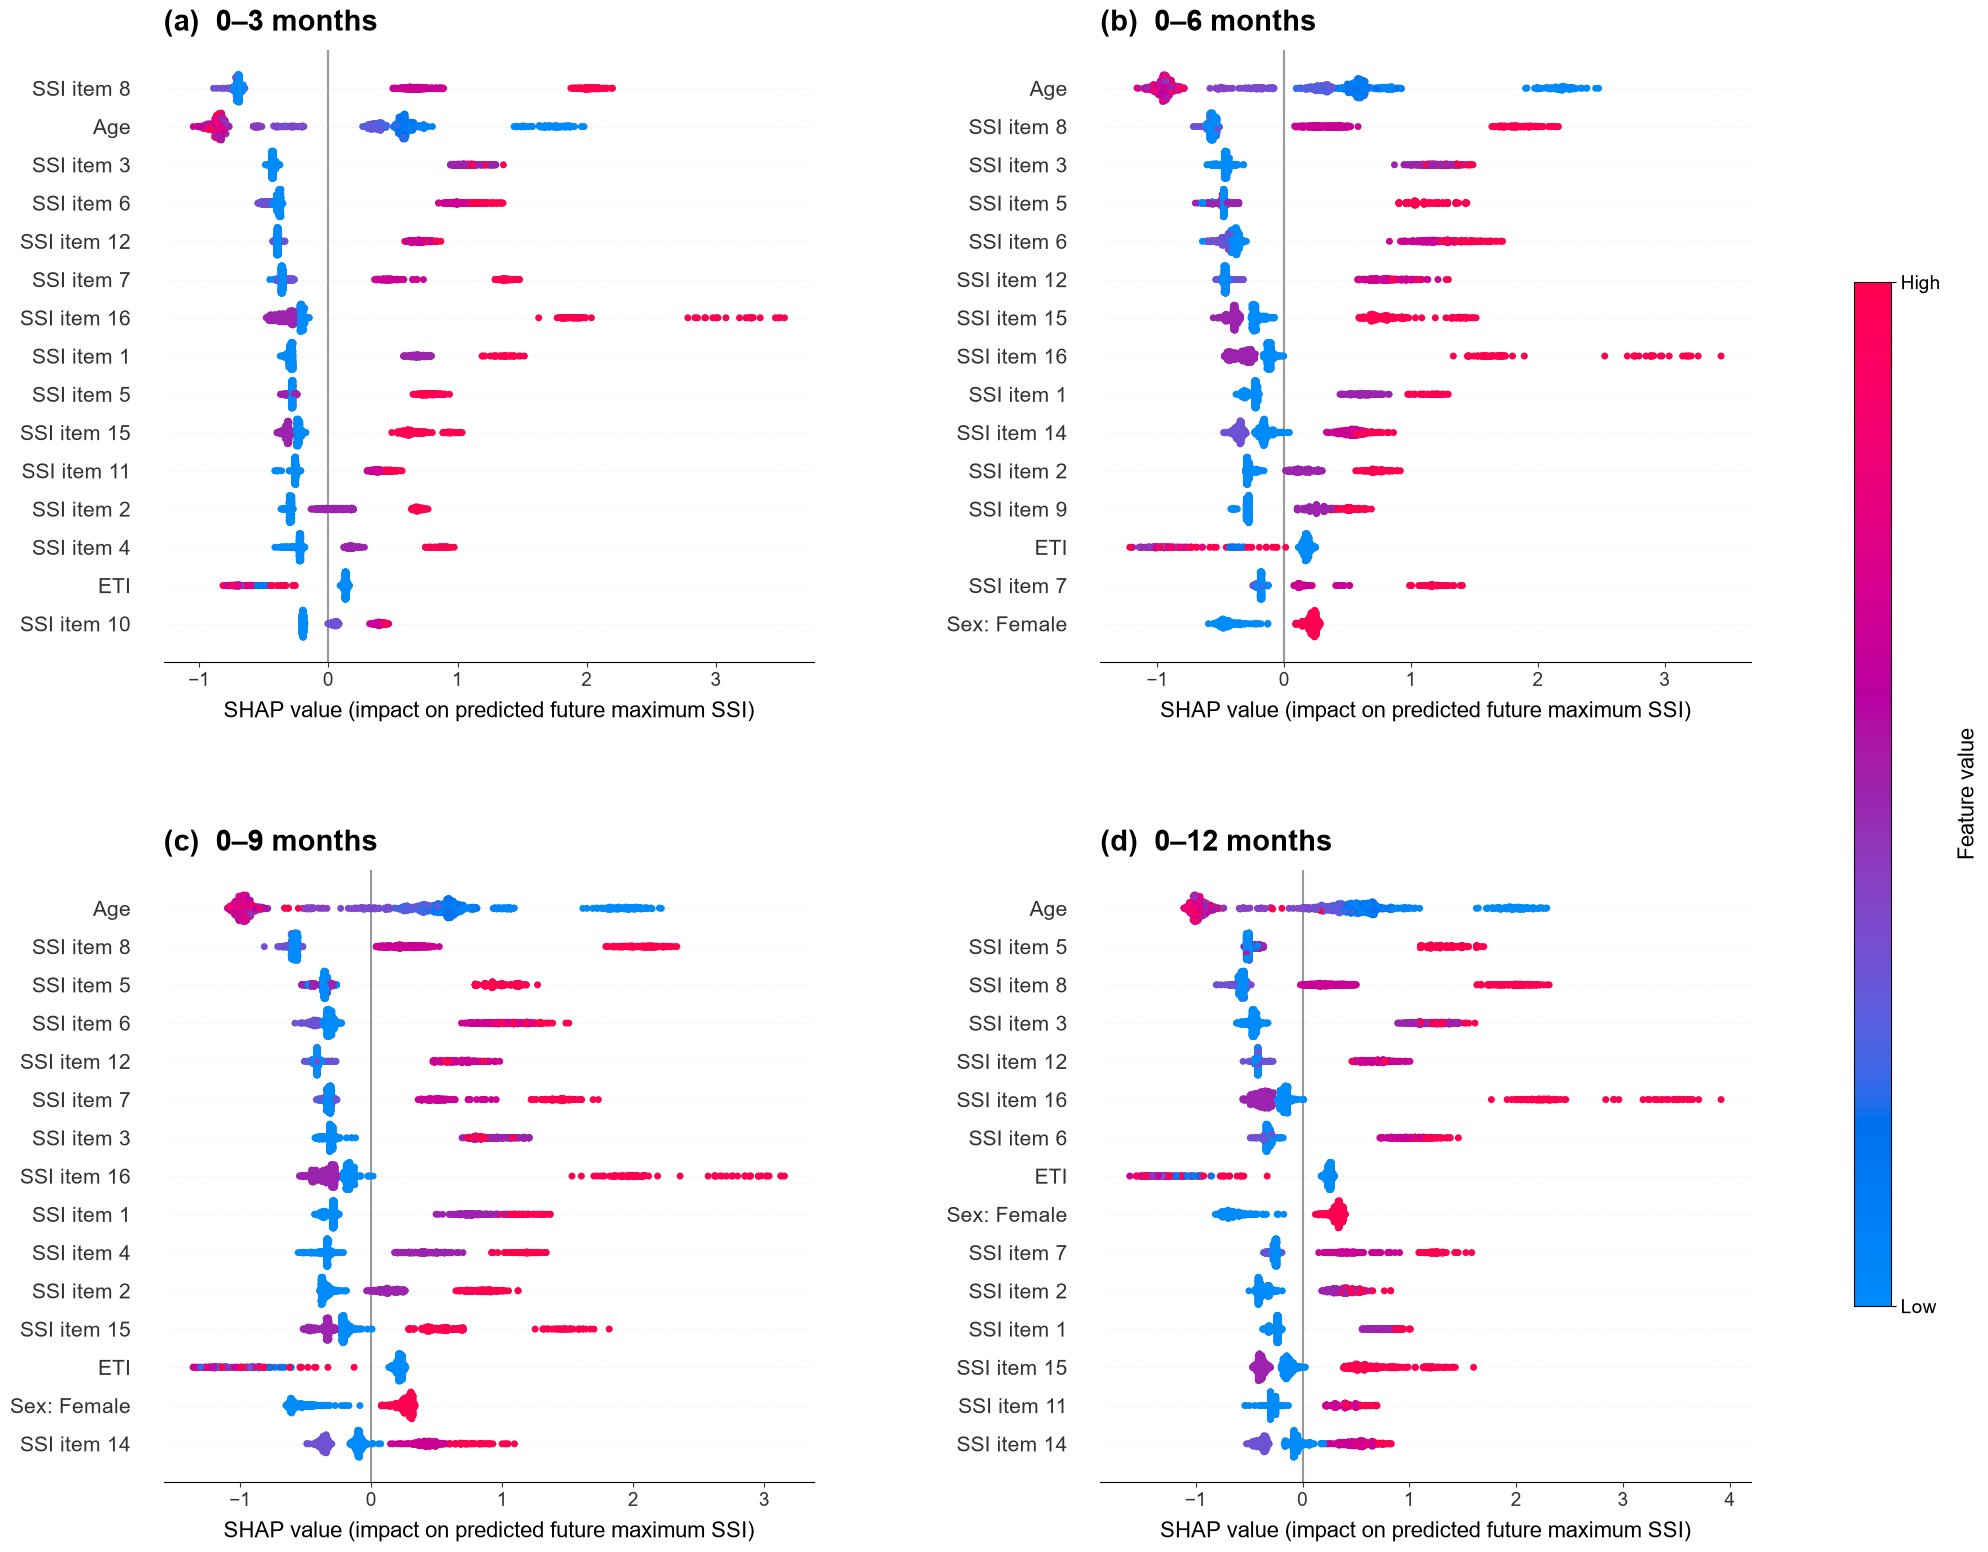

In [10]:
# ============================================================
# REVISED STANDALONE SHAP ANALYSIS
# CELL 3: COMBINED FOUR-PANEL SHAP BEESWARM
# ============================================================

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize


# ------------------------------------------------------------
# 1. Load saved SHAP explanations
# ------------------------------------------------------------

if not SHAP_PATH.exists():

    raise FileNotFoundError(
        "The SHAP explanation file was not found. "
        "Run Cell 2 first."
    )


saved_shap_payload = joblib.load(
    SHAP_PATH
)


if (
    saved_shap_payload.get(
        "analysis_id"
    )
    != ANALYSIS_ID
):

    raise RuntimeError(
        "The saved SHAP file belongs to a different "
        "analysis specification."
    )


shap_explanations = (
    saved_shap_payload[
        "explanations"
    ]
)


for (
    horizon_key,
    horizon_label,
    panel_label,
    horizon_months,
) in HORIZONS:

    if (
        horizon_key
        not in shap_explanations
    ):

        raise KeyError(
            f"SHAP values are missing for "
            f"{horizon_label}."
        )


# ------------------------------------------------------------
# 2. Arial style
# ------------------------------------------------------------

font_manager.findfont(
    font_manager.FontProperties(
        family="Arial"
    ),
    fallback_to_default=False,
)


plt.rcParams.update(
    {
        "font.family":
            "Arial",

        "font.size":
            14,

        "axes.unicode_minus":
            True,

        "pdf.fonttype":
            42,

        "ps.fonttype":
            42,
    }
)


# ------------------------------------------------------------
# 3. Create combined 2 × 2 figure
# ------------------------------------------------------------

plt.close(
    "all"
)


figure, axes = plt.subplots(
    nrows=
        2,

    ncols=
        2,

    figsize=(
        23,
        16,
    ),
)


axes = axes.flatten()


for axis, (
    horizon_key,
    horizon_label,
    panel_label,
    horizon_months,
) in zip(
    axes,
    HORIZONS,
    strict=True,
):

    shap.plots.beeswarm(
        shap_explanations[
            horizon_key
        ],

        max_display=
            15,

        # Prevent a "Sum of other features" row.
        group_remaining_features=
            False,

        show=
            False,

        color_bar=
            False,

        plot_size=
            None,

        ax=
            axis,

        s=
            25,
    )


    axis.set_title(
        f"{panel_label}  "
        f"{horizon_label}",

        fontsize=
            21,

        fontweight=
            "bold",

        loc=
            "left",

        pad=
            14,
    )


    axis.set_xlabel(
        "SHAP value "
        "(impact on predicted future maximum SSI)",

        fontsize=
            16,

        labelpad=
            8,
    )


    axis.tick_params(
        axis=
            "x",

        labelsize=
            14,
    )


    axis.tick_params(
        axis=
            "y",

        labelsize=
            15,
    )


    for label in (
        axis.get_xticklabels()
        + axis.get_yticklabels()
    ):

        label.set_fontfamily(
            "Arial"
        )


# ------------------------------------------------------------
# 4. Shared feature-value colour bar
# ------------------------------------------------------------

scalar_map = ScalarMappable(
    norm=Normalize(
        vmin=0,
        vmax=1,
    ),

    cmap=
        shap.plots.colors.red_blue,
)


scalar_map.set_array(
    []
)


colour_bar_axis = figure.add_axes(
    [
        0.920,  # left
        0.180,  # bottom
        0.016,  # width
        0.640,  # height
    ]
)


colour_bar = figure.colorbar(
    scalar_map,
    cax=colour_bar_axis,
)


colour_bar.set_ticks(
    [
        0,
        1,
    ]
)


colour_bar.set_ticklabels(
    [
        "Low",
        "High",
    ]
)


colour_bar.set_label(
    "Feature value",

    fontsize=
        16,

    labelpad=
        12,
)


colour_bar.ax.tick_params(
    labelsize=
        14,
)


# ------------------------------------------------------------
# 5. Figure spacing
# ------------------------------------------------------------

figure.subplots_adjust(
    left=
        0.185,

    right=
        0.875,

    top=
        0.965,

    bottom=
        0.070,

    hspace=
        0.340,

    wspace=
        0.440,
)


# ------------------------------------------------------------
# 6. Save figure
# ------------------------------------------------------------

BEESWARM_PNG = (
    FIGURE_FOLDER
    / "Figure_SHAP_beeswarm_with_demographics.png"
)

BEESWARM_PDF = (
    FIGURE_FOLDER
    / "Figure_SHAP_beeswarm_with_demographics.pdf"
)

BEESWARM_TIFF = (
    FIGURE_FOLDER
    / "Figure_SHAP_beeswarm_with_demographics.tiff"
)


figure.savefig(
    BEESWARM_PNG,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.15,
)


figure.savefig(
    BEESWARM_PDF,
    bbox_inches="tight",
    pad_inches=0.15,
)


figure.savefig(
    BEESWARM_TIFF,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.15,
)


plt.show()

plt.close(
    figure
)


print(
    "Combined SHAP beeswarm created."
)

print(
    f"\nPNG:\n"
    f"{BEESWARM_PNG}"
)

print(
    f"\nPDF:\n"
    f"{BEESWARM_PDF}"
)

print(
    f"\nTIFF:\n"
    f"{BEESWARM_TIFF}"
)